In [23]:
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
from util_LEFM import K1

In [24]:
plt.rcParams.update({
    'figure.figsize': (8, 6),
    'axes.titlesize': 16,        # Main title
    'axes.labelsize': 14,        # Axis labels
    'xtick.labelsize': 14,       # X-axis tick labels
    'ytick.labelsize': 14,       # Y-axis tick labels
    'legend.fontsize': 12,       # Legend text
    'figure.titlesize': 18       # Figure-level suptitle
})

In [25]:
T_list = np.linspace(0, 3.0, 3001)
Kc_list = np.linspace(0, 3.0, 3001)
Kc_grid, T_grid = np.meshgrid(Kc_list, T_list)
l_grid = np.empty_like(Kc_grid)

l_array = np.power(10, np.linspace(1e-6, 1, 20000))

Kcmin_list = np.empty_like(T_list)
lmax_list = np.empty_like(T_list)

for idx_T, T in enumerate(tqdm(T_list)):
    Kc_array = K1(T, l_array)
    idx_lmax = np.argmin(Kc_array)
    Kcmin_list[idx_T] = Kc_array[idx_lmax]
    lmax_list[idx_T] = l_array[idx_lmax]

    # Reverse the branch from the minimum so that Kc increases for interpolation.
    Kc_branch = Kc_array[idx_lmax::-1]
    if not np.all(Kc_branch[:-1] <= Kc_branch[1:]):
        print(f"Warning: Kc_array is not monotonically decreasing for T={T}")

    l_grid[idx_T] = np.interp(Kc_list, Kc_branch, l_array[idx_lmax::-1], left=np.nan)

np.save("out/phase_diagram_ultralarge_datagrid.npy", {
    'T_grid': T_grid,
    'Kc_grid': Kc_grid,
    'l_grid': l_grid,
    'T_list': T_list,
    'Kc_list': Kc_list,
    'Kcmin_list': Kcmin_list,
    'lmax_list': lmax_list,
})

  0%|          | 0/3001 [00:00<?, ?it/s]

100%|██████████| 3001/3001 [00:01<00:00, 2288.21it/s]


In [26]:
# read the data grid
# data = np.load('SB_phase_diagram_large_datagrid.npy', allow_pickle=True).item()
data = np.load('out/phase_diagram_ultralarge_datagrid.npy', allow_pickle=True).item()
T_grid = data['T_grid']
Kc_grid = data['Kc_grid']
l_grid = data['l_grid']
T_list = data['T_list']
Kcmin_list = data['Kcmin_list']
lmax_list = data['lmax_list']
Kc_list = data['Kc_list']

Text(2.0, 1.8, 'Self-arrested\nruptures')

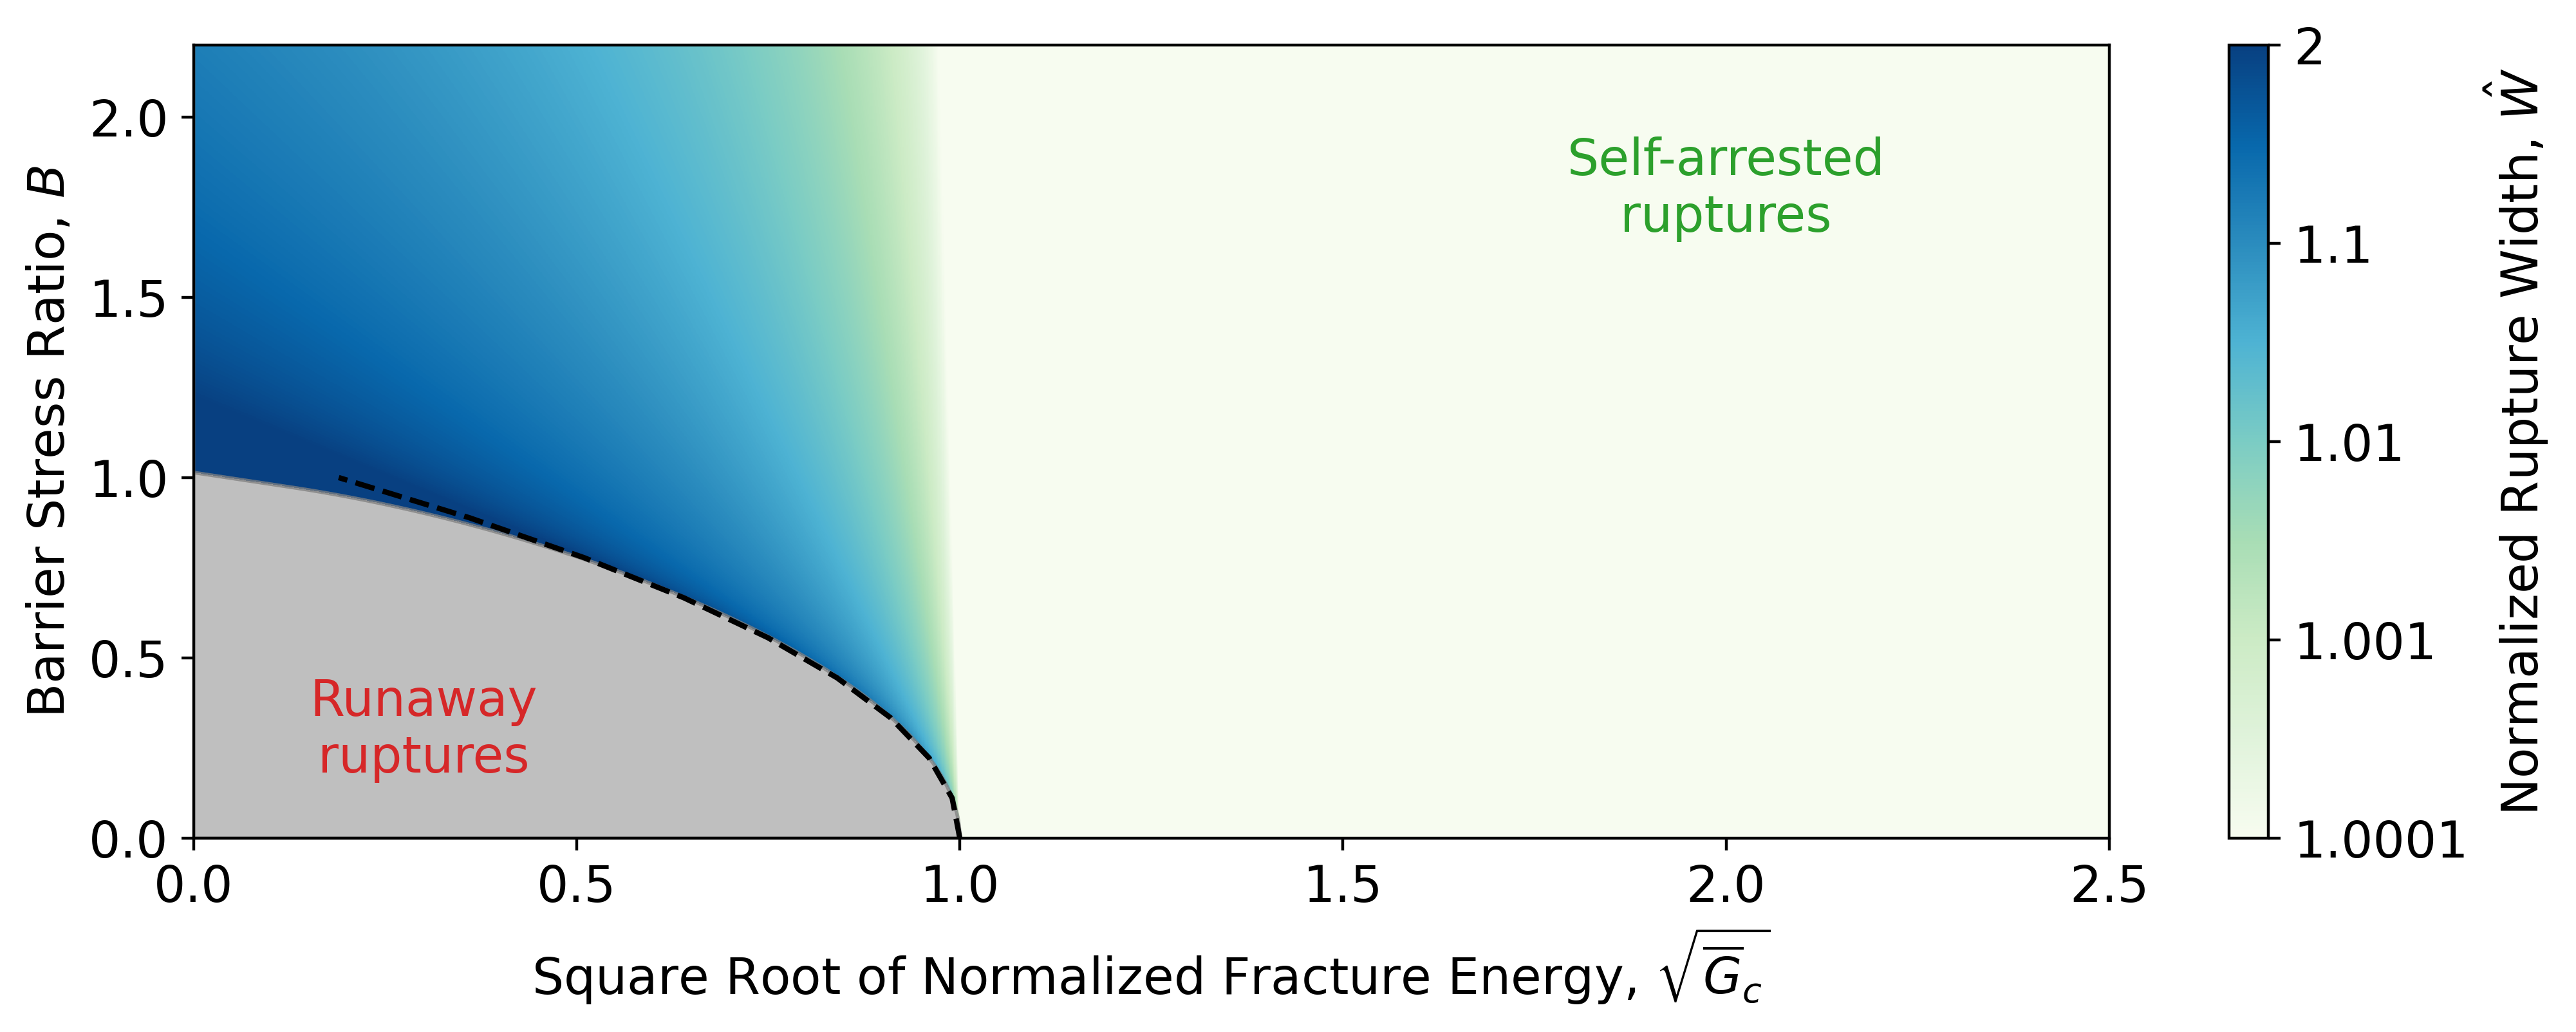

In [27]:
from matplotlib.ticker import FuncFormatter

fig, ax = plt.subplots(figsize=(12, 4), dpi=400)

l_field = ax.pcolormesh(
    Kc_grid, T_grid, np.log10(l_grid-1),
    shading='auto', cmap=plt.get_cmap('GnBu'), vmin=-4, vmax= 0
)

# GnBu


# l_field_stable = ax.pcolormesh(
#     Kc_grid2, T_grid2, np.log10(l_grid2-1),
#     shading='auto', cmap=plt.get_cmap('GnBu'), vmin=-4, vmax=0
# )


# boundary line - numerical
line_boundary = ax.plot(Kcmin_list, T_list, color='grey', linewidth = 1.0, linestyle='solid', alpha = 0.5 )

# boundary line - theoretical
B_boundary_theory = np.linspace(0,1, 10) # (0, 0.813, 10)
Kc_boundary_theory = 1.0  - 8*B_boundary_theory**2/np.pi**2
ax.plot(Kc_boundary_theory, B_boundary_theory, color = 'k', linestyle = 'dashed' )

# Labels
# ax.legend(loc='lower right')
ax.set_xlabel(r'Square Root of Normalized Fracture Energy, $\sqrt{\overline{G}_c}$')
ax.set_ylabel(r'Barrier Stress Ratio, $B$')

ax.set_xlim(0, 2.5)
ax.set_ylim(0, 2.2)

# Add colorbar
cbar = plt.colorbar(l_field, ax=ax, location = 'right' )

# Choose L tick values you want to show
L_ticks = [1.0001, 1.001, 1.01, 1.1, 2]  # example values > 1
log_ticks = np.log10(np.array(L_ticks) - 1)     # convert to log10(L-1)

cbar.set_ticks(log_ticks)
cbar.set_ticklabels([f"{L:.5g}" for L in L_ticks])  # show original L values
cbar.set_label(r"Normalized Rupture Width, $\hat{W}$", fontsize = 14)


# Fill the area bounded by x-axis, y-axis, and (Kcmin_list, T_list) line with grey
ax.fill_betweenx(T_list, 0, Kcmin_list, color='grey', alpha=0.5)

# text in the filled area
ax.text(0.3, 0.3, 'Runaway\nruptures', color='C3', fontsize=14, ha='center', va='center', rotation=0)
ax.text(2.00, 1.80, 'Self-arrested\nruptures', color='C2', fontsize=14, ha='center', va='center', rotation=0)

In [28]:
# Huizinge parameters set

Mag = 3.6
M0 = 10**(1.5*Mag + 9.105)  # in N*m
H = 269
nu = 0.25
dip = 70*np.pi/180

# a little tuning
fd = 0.25 
delta_P = 24e6 
mu = 30e9

In [29]:
ks = (1-2*nu)/(1-nu)*0.5*(  fd+np.sqrt(1+fd**2)*np.sin( 2*dip-np.arctan(fd) )  ) - fd
ks_optimized = (1-2*nu)/(1-nu)*0.5*(  fd+np.sqrt(1+fd**2)  ) - fd

Delta_S = ks * delta_P
print("Delta_S for Huizinge EQ is", Delta_S*1e-6, "MPa")

Delta_S for Huizinge EQ is 2.6743897637302707 MPa


In [30]:
def locate_Huizinge(stressdrop):
    T = Delta_S/stressdrop

    # from Abercrombie and Rice 2005
    radius = ( 7/16 * M0 / stressdrop )**(1/3)  # in m
    slip = M0/(np.pi*mu*radius**2)  # in m
    Gc = 5.25*1e6*slip**1.28

    Kc = np.sqrt( Gc * 2 * mu /(1-nu) )
    
    Kc_bar = Kc / ( np.sqrt(np.pi/2) * stressdrop * np.sqrt(H/np.sin(dip)) )
    return Kc_bar, T

In [31]:
from scipy.interpolate import RegularGridInterpolator

S1_overall = np.linspace(1e6, 10e6, 99)
results = [locate_Huizinge(stressdrop) for stressdrop in S1_overall]
Kcbar_overall, T_Huizinge_overall = zip(*results)



interpolator = RegularGridInterpolator((T_list, Kc_list), l_grid)   

lbar_overall = interpolator( np.array([T_Huizinge_overall, Kcbar_overall]).T )

beta_overall = M0/(  np.pi/4*(1-nu) * S1_overall * (lbar_overall*H)**3  ) 

In [32]:
idx_nonnan = ~np.isnan(beta_overall)
S1_max = np.max(S1_overall[idx_nonnan])
print("Max non-nan S1 is (MPa)", S1_max*1e-6)

Max non-nan S1 is (MPa) 4.765306122448979


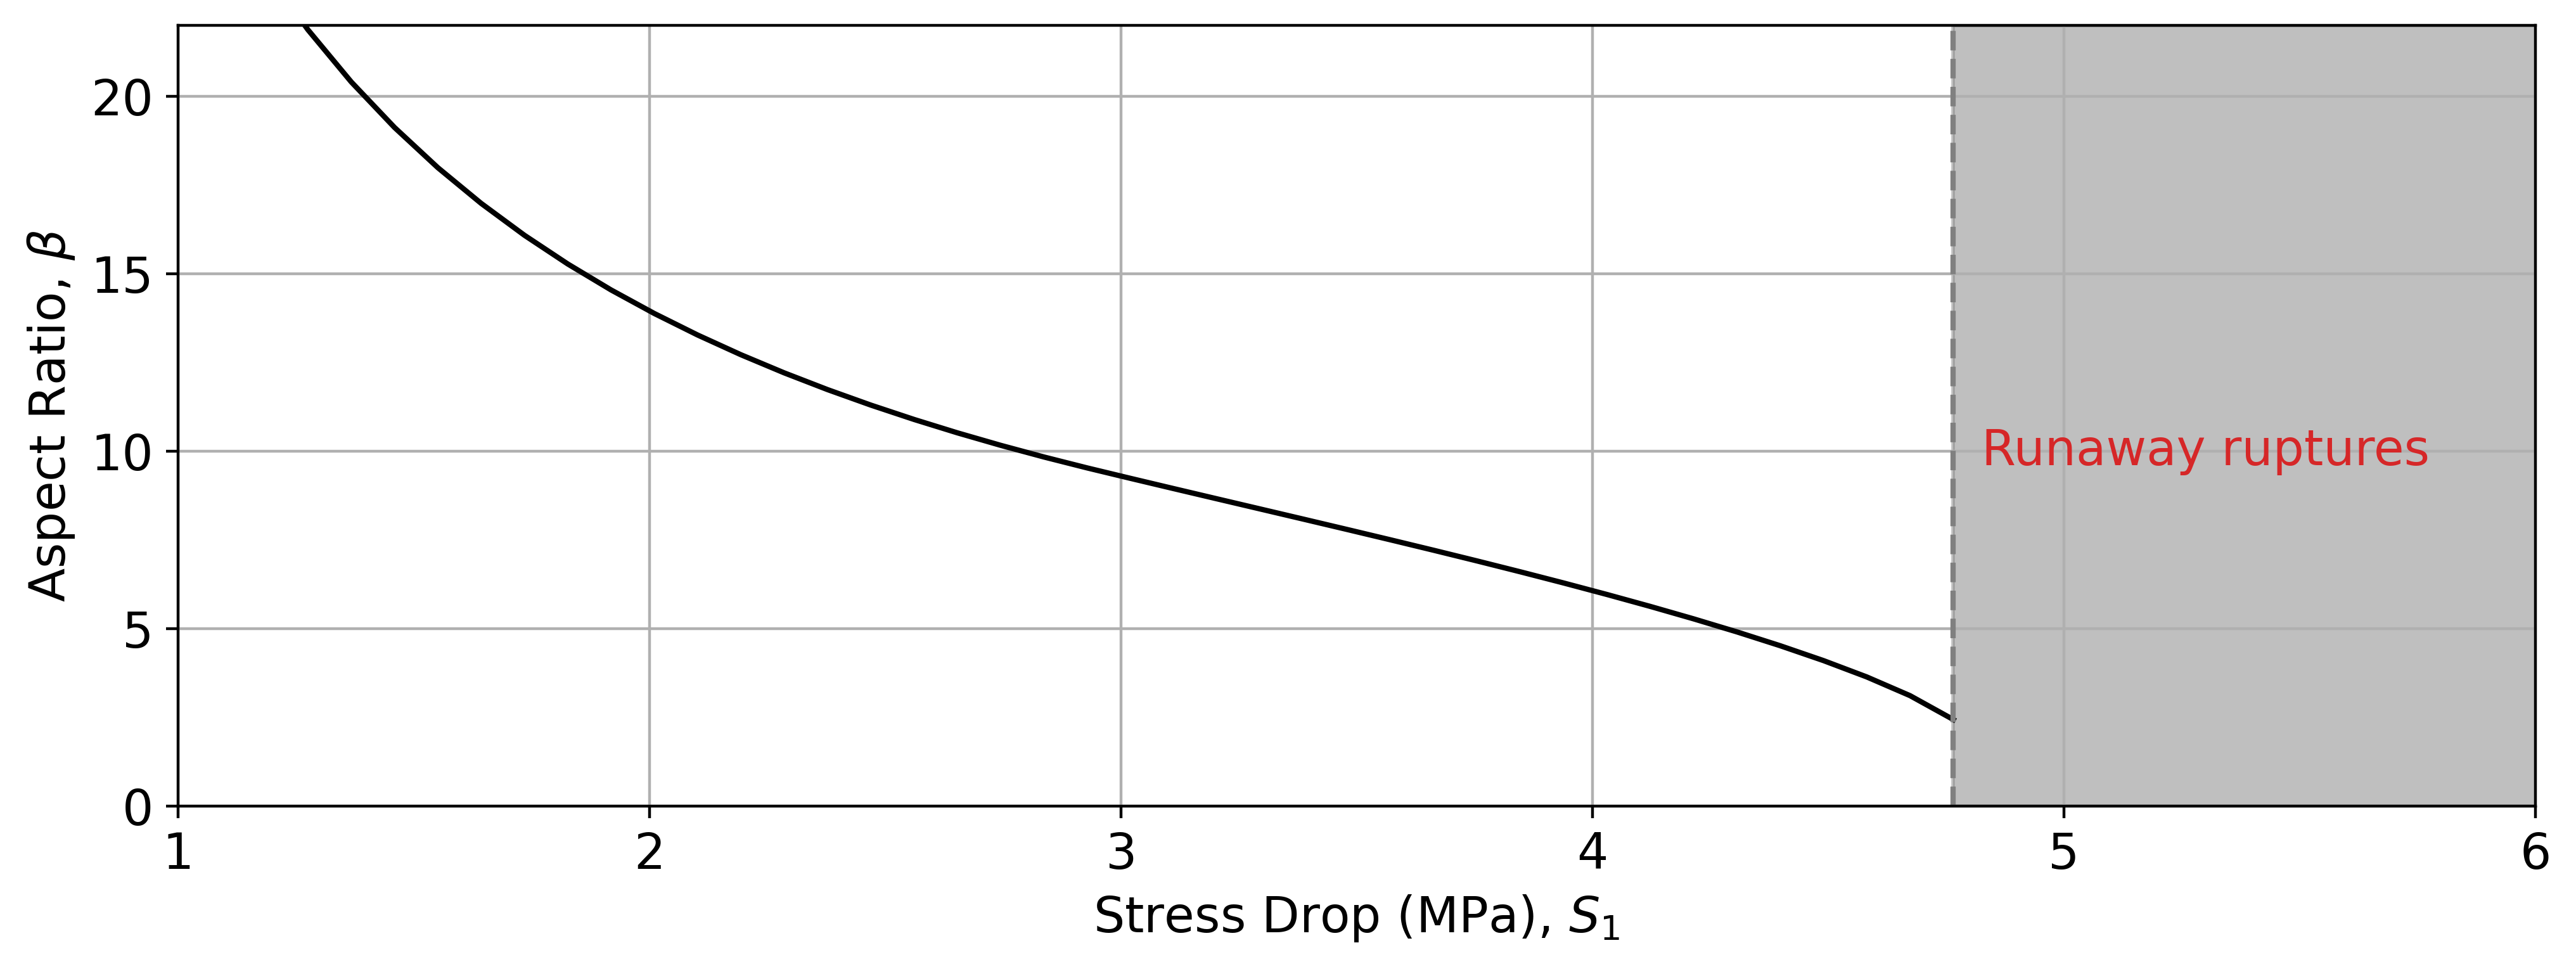

In [33]:
fig, ax = plt.subplots(figsize=(12, 4), dpi=400)
ax.plot(S1_overall * 1e-6, beta_overall, 'black')
ax.plot(np.ones(100)*S1_max*1e-6, np.linspace(0, 22, 100), 'gray', linestyle='--')
ax.fill_betweenx(np.linspace(0, 22, 100), np.ones(100)*S1_max*1e-6, 7, color='grey', alpha=0.5)
ax.text(5.3, 10, 'Runaway ruptures', color='C3', fontsize=14, ha='center', va='center', rotation=0)

ax.grid()
ax.set_ylim(0, 22)
ax.set_xlim(1, 6)


ax.set_xlabel(r'Stress Drop (MPa), $S_1$', fontsize=14)
ax.set_ylabel(r'Aspect Ratio, $\beta$', fontsize=14)
fig.savefig('out/Fig_S5.png',bbox_inches='tight', dpi=400)

In [34]:
S1_pick = 4e6
beta_pick = np.interp(S1_pick, S1_overall, beta_overall)
T_pick = np.interp(S1_pick, S1_overall, T_Huizinge_overall)
Kcbar_pick = np.interp(S1_pick, S1_overall, Kcbar_overall) 
Kc_pick = Kcbar_pick * ( np.sqrt(np.pi/2) * S1_pick * np.sqrt(H/np.sin(dip)) )
Gc_pick = Kc_pick**2 * (1-nu)/(2*mu)

print("Aspect ratio for S1 =", S1_pick*1e-6, "MPa is", beta_pick)
print("Barrier stress ratio for S1 =", S1_pick*1e-6, "MPa is", T_pick)
print("Critical stress intensity factor for S1 =", S1_pick*1e-6, "MPa is", Kc_pick)
print("Critical fracture energy for S1 =", S1_pick*1e-6, "MPa is", Gc_pick * 1e-6, "MJ/m^2")

Aspect ratio for S1 = 4.0 MPa is 6.069623635336931
Barrier stress ratio for S1 = 4.0 MPa is 0.6686763728794214
Critical stress intensity factor for S1 = 4.0 MPa is 71215716.26832141
Critical fracture energy for S1 = 4.0 MPa is 0.06339597804512573 MJ/m^2


In [35]:
S1_PD = np.linspace(1e6, 10e6, 10)
results_PD = [locate_Huizinge(stressdrop) for stressdrop in S1_PD]
Kcbar_PD, T_Huizinge_PD = zip(*results_PD)

Text(0.97, 0.38, '')

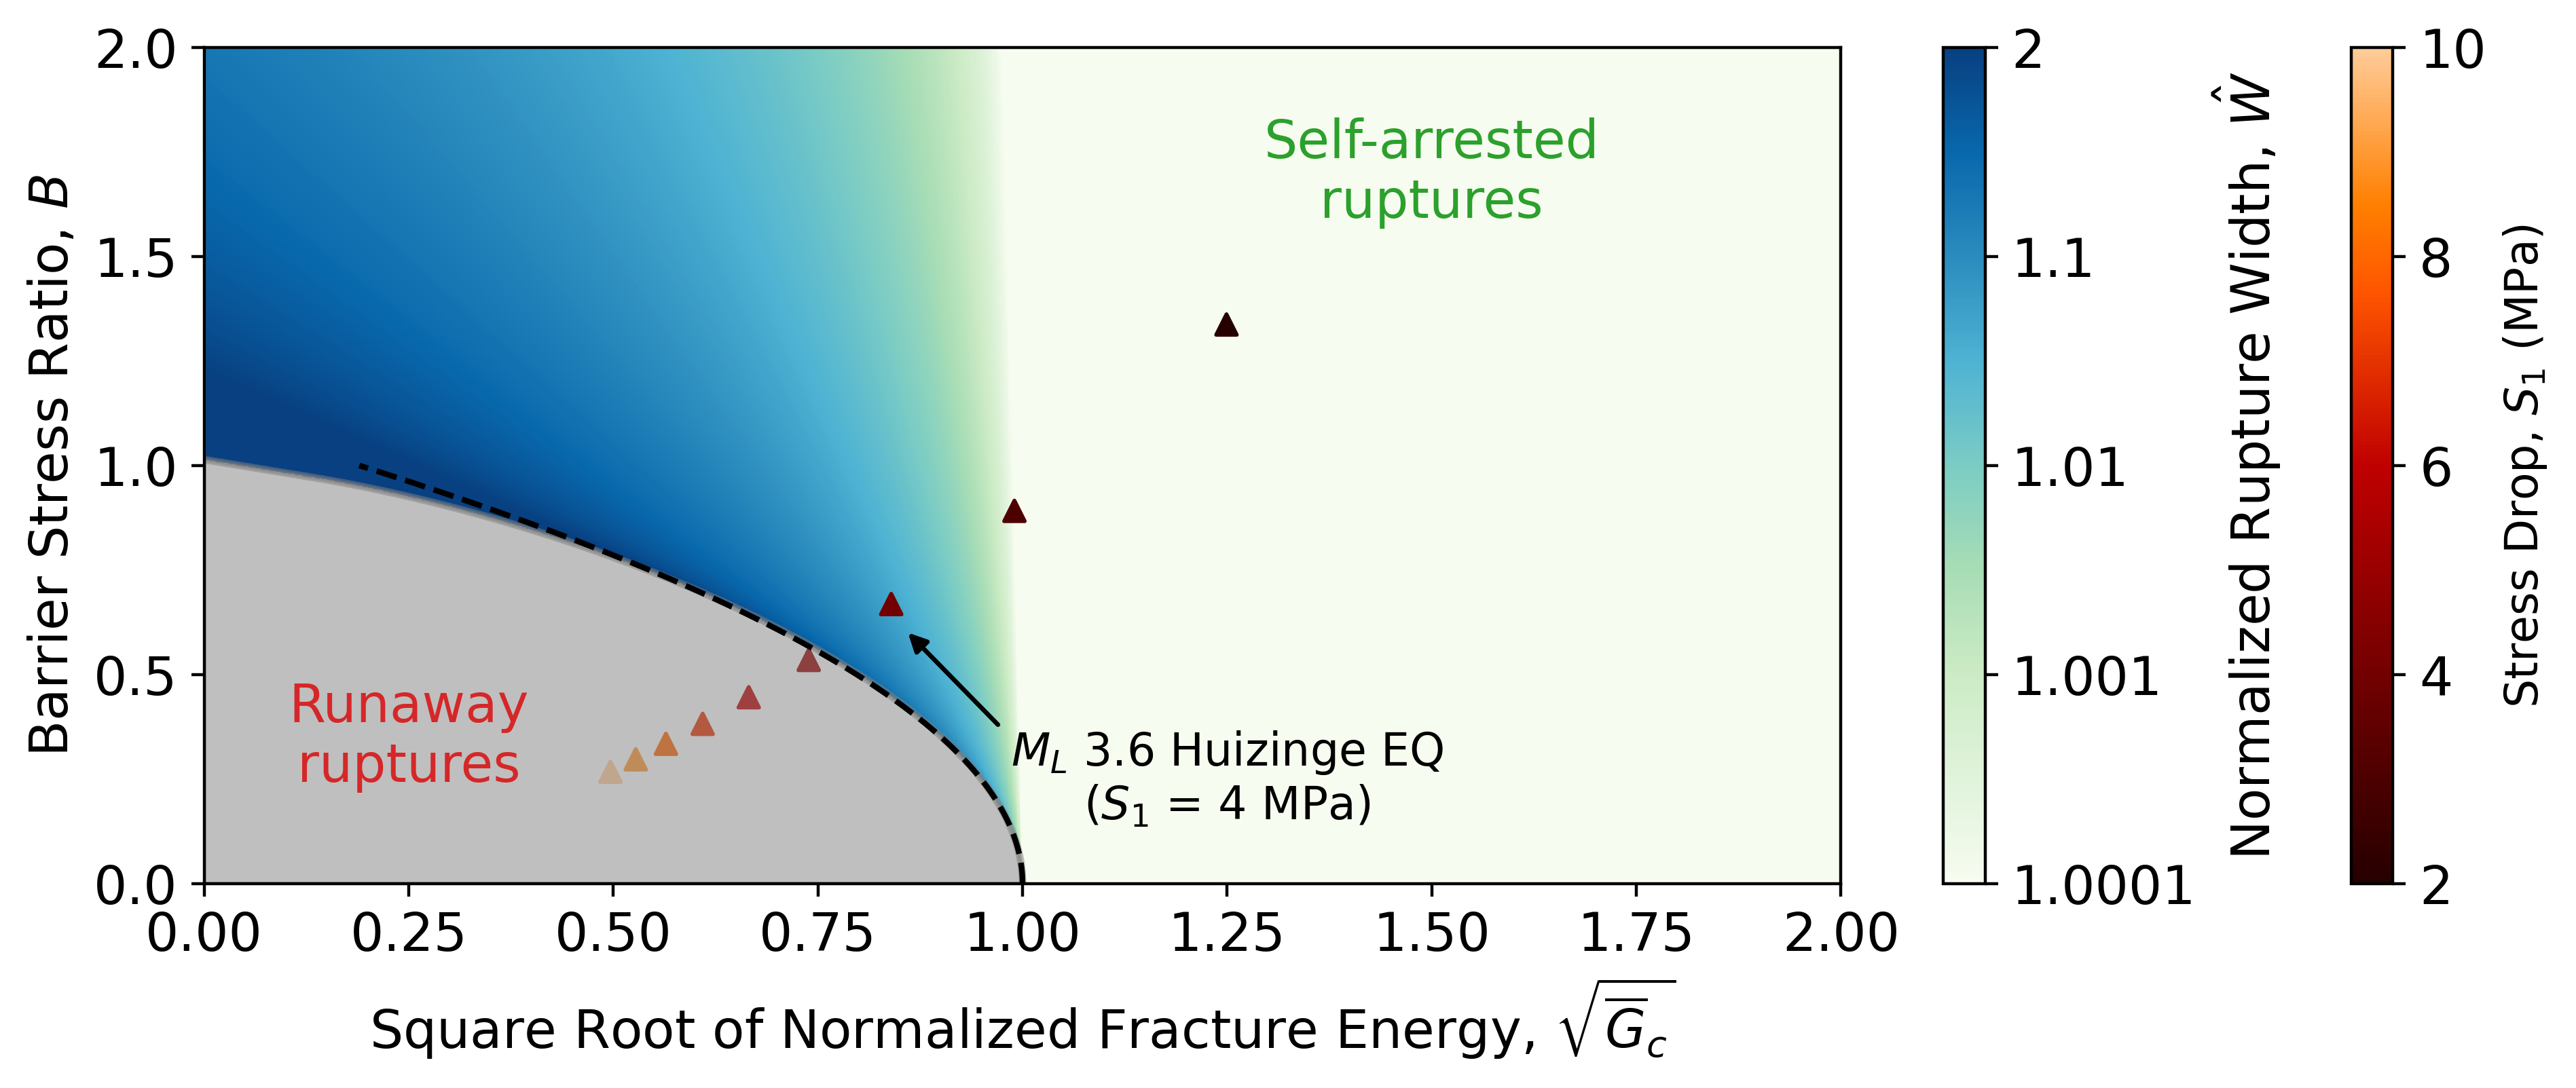

In [36]:
fig, ax = plt.subplots(figsize=(12, 4), dpi=400)

l_field = ax.pcolormesh(
    Kc_grid, T_grid, np.log10(l_grid-1),
    shading='auto', cmap=plt.get_cmap('GnBu'), vmin=-4, vmax= 0 )

# GnBu


# l_field_stable = ax.pcolormesh(
#     Kc_grid2, T_grid2, np.log10(l_grid2-1),
#     shading='auto', cmap=plt.get_cmap('GnBu'), vmin=-4, vmax=0
# )


# boundary line - numerical
line_boundary = ax.plot(Kcmin_list, T_list, color='grey', linewidth = 2.0, linestyle='solid', alpha = 0.5 )

# boundary line - theoretical
B_boundary_theory = np.linspace(0, 1, 100) # (0, 0.813, 10)
Kc_boundary_theory = 1.0  - 8*B_boundary_theory**2/np.pi**2
ax.plot(Kc_boundary_theory, B_boundary_theory, color = 'k', linestyle = 'dashed' )


# Huizinge
cmap = 'gist_heat'
norm = plt.Normalize(vmin = 1, vmax = 11)   # MPa

scatter = ax.scatter(
    Kcbar_PD,
    T_Huizinge_PD,
    c = S1_PD * 1e-6,      # scalar values in MPa
    cmap=cmap,
    norm=norm,
    marker='^',
    s=30
)

cbar_Huizinge = fig.colorbar(scatter, ax=ax, location="right", pad=0.04)
cbar_Huizinge.set_label(r'Stress Drop, $S_1$ (MPa)', fontsize=12)

# Show only the colorbar range from 1 to 10
cbar_Huizinge.ax.set_ylim(2, 10)

# Optional: choose ticks only within the shown range
# cbar_Huizinge.set_ticks([1, 2, 4, 6, 8, 10])

ax.set_xlabel(r'Square Root of Normalized Fracture Energy, $\sqrt{\overline{G}_c}$')
ax.set_ylabel(r'Barrier Stress Ratio, $B$')

ax.set_xlim(0, 2.0)
ax.set_ylim(0, 2.0) # 2.8

# Add colorbar
cbar = plt.colorbar(l_field, ax=ax, location = 'right' )

# Choose L tick values you want to show
L_ticks = [1.0001, 1.001, 1.01, 1.1, 2]  # example values > 1
log_ticks = np.log10(np.array(L_ticks) - 1)     # convert to log10(L-1)

cbar.set_ticks(log_ticks)
cbar.set_ticklabels([f"{L:.5g}" for L in L_ticks])  # show original L values
cbar.set_label(r"Normalized Rupture Width, $\hat{W}$", fontsize = 14)


# Fill the area bounded by x-axis, y-axis, and (Kcmin_list, T_list) line with grey
ax.fill_betweenx(T_list, 0, Kcmin_list, color='grey', alpha=0.5)

# text in the filled area
ax.text(0.25, 0.35, 'Runaway\nruptures', color='C3', fontsize=14, ha='center', va='center', rotation=0)
ax.text(1.50, 1.70, 'Self-arrested\nruptures', color='C2', fontsize=14, ha='center', va='center', rotation=0)

# Huizinge text
ax.text(1.25, 0.25, r'$M_L$ 3.6 Huizinge EQ'+'\n'+r'($S_1$ = 4 MPa)', color='k', fontsize=12, ha='center', va='center', rotation=0)

# Huizinge arrow
# version 1
# ax.arrow(0.98, 0.39, -0.06, 0.06, head_width=0.02, head_length=0.02, fc='k', ec='k')
# version 2
ax.annotate(
    '',
    xy=(0.86, 0.6),        # arrow head
    xytext=(0.97, 0.38),    # arrow tail
    arrowprops=dict(
        arrowstyle='-|>',
        linewidth=1.2,
        color='k',
        mutation_scale=10,
        shrinkA=0,
        shrinkB=0
    )
)


In [37]:
fig.savefig('out/Fig_2D.png',bbox_inches='tight', dpi=400)